# Ejercicio — Greedy Best-First Search


### Recorrido dentro de una ciudad

Una persona se encuentra en la **Terminal** y necesita llegar al **Hospital**.

El mapa de la ciudad contiene distintas zonas y rutas posibles. El algoritmo **Greedy Best-First Search** utilizará una heurística `h(n)` que representa una **estimación de qué tan cerca parece estar cada lugar del Hospital**.

### Objetivo

Observar cómo diferentes valores de heurística pueden hacer que Greedy:

- explore diferentes zonas;
- seleccione diferentes ramas;
- encuentre diferentes caminos;
- cambie su comportamiento sin modificar el grafo.

Durante toda la práctica:

> **No se modifica el algoritmo Greedy.**  
> **No se modifican las conexiones del grafo.**  
> **Solo se modifican los valores heurísticos.**


# 1. Librerías

Utilizaremos:

- `heapq` para la cola de prioridad;
- `networkx` para construir el grafo;
- `matplotlib` para visualizarlo.


In [8]:
import heapq
import networkx as nx
import matplotlib.pyplot as plt


# 2. Grafo de la ciudad

Cada lugar representa un estado.

Las conexiones indican que existe una ruta directa entre dos lugares.


In [6]:
grafo = {
    'Terminal': ['Centro', 'Mercado', 'Universidad'],
    'Centro': ['Terminal', 'Museo', 'Parque'],
    'Mercado': ['Terminal', 'Parque', 'Estadio'],
    'Universidad': ['Terminal', 'Biblioteca'],
    'Museo': ['Centro', 'Clínica'],
    'Parque': ['Centro', 'Mercado', 'Clínica'],
    'Estadio': ['Mercado', 'Avenida'],
    'Biblioteca': ['Universidad', 'Avenida'],
    'Clínica': ['Museo', 'Parque', 'Hospital'],
    'Avenida': ['Estadio', 'Biblioteca', 'Hospital'],
    'Hospital': ['Clínica', 'Avenida']
}

inicio = 'Terminal'
meta = 'Hospital'


# 3. Heurística original

La heurística indica qué tan prometedor parece cada lugar para llegar al Hospital.

Recuerda:

- menor `h(n)` = parece más cerca de la meta;
- mayor `h(n)` = parece más lejos;
- la meta tiene `h(Hospital) = 0`.


In [3]:
heuristica = {
    'Terminal': 12,
    'Centro': 8,
    'Mercado': 6,
    'Universidad': 10,
    'Museo': 7,
    'Parque': 5,
    'Estadio': 4,
    'Biblioteca': 6,
    'Clínica': 2,
    'Avenida': 3,
    'Hospital': 0
}


# 4. Visualización del grafo


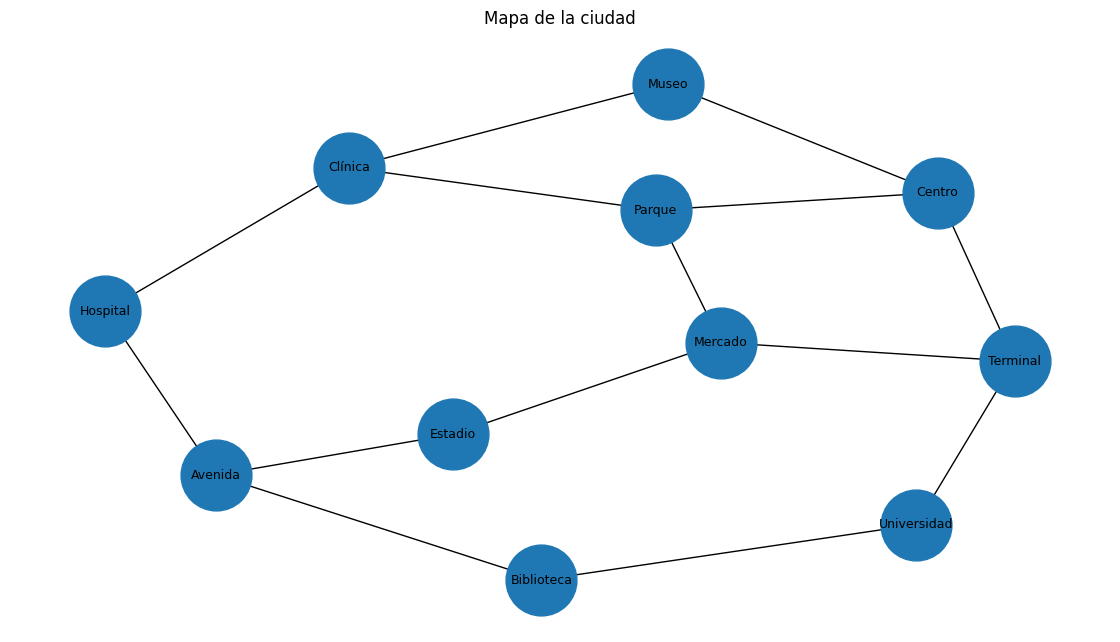

In [ ]:
G = nx.Graph()

for nodo, vecinos in grafo.items():
    G.add_node(nodo)

    for vecino in vecinos:
        G.add_edge(nodo, vecino)

pos = nx.spring_layout(G, seed=8)

plt.figure(figsize=(11, 6))

nx.draw(
    G,
    pos,
    with_labels=True,
    node_size=2600,
    font_size=9
)

plt.title("Mapa de la ciudad")
plt.show()


# 5. Algoritmo Greedy Best-First Search

Este es el algoritmo explicado en clase.

**No debe modificarse durante el ejercicio.**


In [9]:
def greedy(grafo, heuristica, inicio, meta, mostrar=True):

    cola = [(heuristica[inicio], 0, inicio, [inicio])]
    contador = 1
    visitados = set()
    orden = []

    while cola:

        if mostrar:
            print(
                'Pendientes:',
                [(n, h) for h, _, n, _ in sorted(cola)]
            )

        h, _, nodo, camino = heapq.heappop(cola)

        if nodo in visitados:
            continue

        visitados.add(nodo)
        orden.append(nodo)

        if mostrar:
            print(
                'Explorando:', nodo,
                '| h =', h,
                '| ruta:', ' -> '.join(camino)
            )

        if nodo == meta:
            return orden, camino

        for vecino in grafo.get(nodo, []):

            if vecino not in visitados:

                heapq.heappush(
                    cola,
                    (
                        heuristica[vecino],
                        contador,
                        vecino,
                        camino + [vecino]
                    )
                )

                contador += 1

    return orden, None


# Caso 1. Heurística original

Ejecuta Greedy utilizando los valores heurísticos originales.

Antes de ejecutar, observa los vecinos de `Terminal`:

- Centro → h = 8
- Mercado → h = 6
- Universidad → h = 10

### Predicción

¿Hacia cuál crees que irá primero Greedy? RESPUESTA: Mercado


In [ ]:
orden, camino = greedy(
    grafo,
    heuristica,
    inicio,
    meta
)

print("\nOrden de exploración:", orden)
print("Camino encontrado:", camino)


Pendientes: [('Terminal', 12)]
Explorando: Terminal | h = 12 | ruta: Terminal
Pendientes: [('Mercado', 6), ('Centro', 8), ('Universidad', 10)]
Explorando: Mercado | h = 6 | ruta: Terminal -> Mercado
Pendientes: [('Estadio', 4), ('Parque', 5), ('Centro', 8), ('Universidad', 10)]
Explorando: Estadio | h = 4 | ruta: Terminal -> Mercado -> Estadio
Pendientes: [('Avenida', 3), ('Parque', 5), ('Centro', 8), ('Universidad', 10)]
Explorando: Avenida | h = 3 | ruta: Terminal -> Mercado -> Estadio -> Avenida
Pendientes: [('Hospital', 0), ('Parque', 5), ('Biblioteca', 6), ('Centro', 8), ('Universidad', 10)]
Explorando: Hospital | h = 0 | ruta: Terminal -> Mercado -> Estadio -> Avenida -> Hospital

Orden de exploración: ['Terminal', 'Mercado', 'Estadio', 'Avenida', 'Hospital']
Camino encontrado: ['Terminal', 'Mercado', 'Estadio', 'Avenida', 'Hospital']


## Preguntas — Caso 1

1. ¿Qué lugar seleccionó Greedy después de Terminal?
Mercado
2. ¿Por qué eligió ese lugar? Por que es el demnor valor hueristico
3. ¿Cuál fue el orden de exploración? Orden de exploración: ['Terminal', 'Mercado', 'Estadio', 'Avenida', 'Hospital']

4. ¿Cuál fue el camino encontrado hasta el Hospital?Camino encontrado: ['Terminal', 'Mercado', 'Estadio', 'Avenida', 'Hospital']

5. ¿Greedy tomó sus decisiones considerando las conexiones recorridas o solamente los valores de `h(n)`? ambas, ya que en el algoritmo los nodos que ya son visitados se toman en cuenta para no volver a pasar por ahi


# Caso 2. Cambiar una o dos heurísticas

Ahora vamos a cambiar únicamente dos valores.

Modifica:

```text
Mercado: 6 → 11
Centro: 8 → 4
```

El grafo permanece exactamente igual.


In [10]:
heuristica = {
    'Terminal': 12,
    'Centro': 4,          # MODIFICADO
    'Mercado': 11,        # MODIFICADO
    'Universidad': 10,
    'Museo': 7,
    'Parque': 5,
    'Estadio': 4,
    'Biblioteca': 6,
    'Clínica': 2,
    'Avenida': 3,
    'Hospital': 0
}

orden, camino = greedy(
    grafo,
    heuristica,
    inicio,
    meta
)

print("\nOrden de exploración:", orden)
print("Camino encontrado:", camino)


Pendientes: [('Terminal', 12)]
Explorando: Terminal | h = 12 | ruta: Terminal
Pendientes: [('Centro', 4), ('Universidad', 10), ('Mercado', 11)]
Explorando: Centro | h = 4 | ruta: Terminal -> Centro
Pendientes: [('Parque', 5), ('Museo', 7), ('Universidad', 10), ('Mercado', 11)]
Explorando: Parque | h = 5 | ruta: Terminal -> Centro -> Parque
Pendientes: [('Clínica', 2), ('Museo', 7), ('Universidad', 10), ('Mercado', 11), ('Mercado', 11)]
Explorando: Clínica | h = 2 | ruta: Terminal -> Centro -> Parque -> Clínica
Pendientes: [('Hospital', 0), ('Museo', 7), ('Museo', 7), ('Universidad', 10), ('Mercado', 11), ('Mercado', 11)]
Explorando: Hospital | h = 0 | ruta: Terminal -> Centro -> Parque -> Clínica -> Hospital

Orden de exploración: ['Terminal', 'Centro', 'Parque', 'Clínica', 'Hospital']
Camino encontrado: ['Terminal', 'Centro', 'Parque', 'Clínica', 'Hospital']


## Preguntas — Caso 2

1. ¿Qué lugar seleccionó ahora después de Terminal?
Seleccionó el **Centro**.

2. ¿Fue diferente al Caso 1?
Sí, en el Caso 1 se seleccionó el Mercado.

3. ¿Cambió el camino encontrado?
Sí, el camino cambió por completo.

4. ¿Qué valores provocaron el cambio?
La reducción de la heurística del Centro (de 8 a 4) y el incremento de la del Mercado (de 6 a 11), lo que hizo que Centro se volviera la opción más atractiva en el primer nivel.

5. ¿Se modificó alguna conexión del mapa?
No, la estructura y conexiones del grafo se mantuvieron exactamente iguales.

6. ¿Qué demuestra este resultado acerca de la importancia de la heurística?
Demuestra que la heurística guía el comportamiento del algoritmo de búsqueda. Al modificar únicamente los valores de estimación subjetiva de distancia (`h`), el algoritmo puede cambiar radicalmente su toma de decisiones local y encontrar rutas completamente distintas sin necesidad de alterar las conexiones físicas del mapa real.

# Caso 3. Favorecer una rama

Ahora queremos hacer que Greedy considere más prometedora la siguiente zona:

```text
Terminal → Universidad → Biblioteca → Avenida → Hospital
```

Para favorecer esta rama utilizaremos valores pequeños en esos estados.


In [ ]:
heuristica = {
    'Terminal': 12,
    'Centro': 9,
    'Mercado': 8,
    'Universidad': 3,      # Favorecido
    'Museo': 7,
    'Parque': 6,
    'Estadio': 5,
    'Biblioteca': 2,       # Favorecido
    'Clínica': 4,
    'Avenida': 1,          # Favorecido
    'Hospital': 0
}

orden, camino = greedy(
    grafo,
    heuristica,
    inicio,
    meta
)

print("\nOrden de exploración:", orden)
print("Camino encontrado:", camino)


Pendientes: [('Terminal', 12)]
Explorando: Terminal | h = 12 | ruta: Terminal
Pendientes: [('Universidad', 3), ('Mercado', 8), ('Centro', 9)]
Explorando: Universidad | h = 3 | ruta: Terminal -> Universidad
Pendientes: [('Biblioteca', 2), ('Mercado', 8), ('Centro', 9)]
Explorando: Biblioteca | h = 2 | ruta: Terminal -> Universidad -> Biblioteca
Pendientes: [('Avenida', 1), ('Mercado', 8), ('Centro', 9)]
Explorando: Avenida | h = 1 | ruta: Terminal -> Universidad -> Biblioteca -> Avenida
Pendientes: [('Hospital', 0), ('Estadio', 5), ('Mercado', 8), ('Centro', 9)]
Explorando: Hospital | h = 0 | ruta: Terminal -> Universidad -> Biblioteca -> Avenida -> Hospital

Orden de exploración: ['Terminal', 'Universidad', 'Biblioteca', 'Avenida', 'Hospital']
Camino encontrado: ['Terminal', 'Universidad', 'Biblioteca', 'Avenida', 'Hospital']


## Preguntas — Caso 3

1. ¿Greedy seleccionó Universidad después de Terminal?
Sí, la seleccionó inmediatamente después.

2. ¿Por qué Universidad tuvo prioridad sobre Centro y Mercado?
Porque se le asignó un valor heurístico mucho menor (h(Universidad) = 3) en comparación con Centro (h = 9) y Mercado (h = 8). Al ser una búsqueda codiciosa (Greedy), siempre se prioriza el nodo con el menor valor de heurística disponible.

3. ¿Qué ocurrió al llegar a Biblioteca?
Al llegar a Biblioteca, el algoritmo expandió sus vecinos y evaluó la heurística de Avenida (h = 1). Como este era el menor valor en la cola de prioridad, continuó su camino hacia Avenida sin desviarse.

4. ¿Qué camino encontró Greedy?
Encontró la ruta:['Terminal', 'Universidad', 'Biblioteca', 'Avenida', 'Hospital']

5. ¿Qué nodos tuvieron los valores heurísticos más pequeños?
Los nodos de la ruta elegida: Hospital (0), Avenida (1), Biblioteca (2) y Universidad (3).

6. ¿El algoritmo conocía de antemano el camino completo hasta el Hospital?
No, Greedy toma decisiones de forma puramente local (paso a paso), eligiendo en cada momento el nodo vecino no visitado que parece estar más cerca de la meta basándose únicamente en el valor h(n).

# Caso 4. Favorecer otra rama

Ahora queremos favorecer una ruta diferente:

```text
Terminal → Centro → Museo → Clínica → Hospital
```

En este caso tú debes modificar las heurísticas.

### Condiciones

- `Centro` debe ser más atractivo que `Mercado` y `Universidad`.
- Desde `Centro`, `Museo` debe ser más atractivo que `Parque`.
- `Clínica` debe tener un valor pequeño.
- `Hospital` debe conservar `h = 0`.

Completa los valores.


In [11]:
heuristica = {
    'Terminal': 12,
    'Centro': 4,          # Muy atractivo
    'Mercado': 10,        # No atractivo
    'Universidad': 10,    # No atractivo
    'Museo': 3,           # Más atractivo que Parque
    'Parque': 6,          # Menos atractivo que Museo
    'Estadio': 8,
    'Biblioteca': 8,
    'Clínica': 2,         # Valor pequeño
    'Avenida': 8,
    'Hospital': 0
}

orden, camino = greedy(
    grafo,
    heuristica,
    inicio,
    meta
)

print("\nOrden de exploración:", orden)
print("Camino encontrado:", camino)

Pendientes: [('Terminal', 12)]
Explorando: Terminal | h = 12 | ruta: Terminal
Pendientes: [('Centro', 4), ('Mercado', 10), ('Universidad', 10)]
Explorando: Centro | h = 4 | ruta: Terminal -> Centro
Pendientes: [('Museo', 3), ('Parque', 6), ('Mercado', 10), ('Universidad', 10)]
Explorando: Museo | h = 3 | ruta: Terminal -> Centro -> Museo
Pendientes: [('Clínica', 2), ('Parque', 6), ('Mercado', 10), ('Universidad', 10)]
Explorando: Clínica | h = 2 | ruta: Terminal -> Centro -> Museo -> Clínica
Pendientes: [('Hospital', 0), ('Parque', 6), ('Parque', 6), ('Mercado', 10), ('Universidad', 10)]
Explorando: Hospital | h = 0 | ruta: Terminal -> Centro -> Museo -> Clínica -> Hospital

Orden de exploración: ['Terminal', 'Centro', 'Museo', 'Clínica', 'Hospital']
Camino encontrado: ['Terminal', 'Centro', 'Museo', 'Clínica', 'Hospital']


## Preguntas — Caso 4

1. ¿Qué valor asignaste a Centro?
Para favorecer esta ruta de manera efectiva, se debió asignar un valor bajo a Centro (por ejemplo, `h(Centro) = 4`), mientras que Mercado y Universidad debían tener valores notablemente más altos (como `h = 8` o `h = 10`). *(Nota: Dejar todos en 0 causa que explore en base al orden de inserción/contador, lo cual no es el uso correcto de la heurística)*.

2. ¿Qué valores asignaste a Mercado y Universidad?
Se les debe asignar valores altos para desalentar al algoritmo de ir por esas rutas. Por ejemplo, `Mercado: 10` y `Universidad: 10`.

3. ¿Qué valor asignaste a Museo?
Un valor pequeño, por ejemplo `h(Museo) = 3`.

4. ¿Qué valor asignaste a Parque?
Un valor más alto que Museo para que Greedy no tome la ruta del Parque, por ejemplo `h(Parque) = 6`.

5. ¿Lograste obtener la ruta propuesta?
Sí, asignando valores descendentes a lo largo de la ruta deseada (`Terminal -> Centro (4) -> Museo (3) -> Clínica (2) -> Hospital (0)`) y valores altos a los caminos alternativos.

6. Si no salió correctamente al primer intento, ¿qué heurística tuviste que modificar?
Se tuvo que ajustar la de los nodos vecinos alternativos (como `Parque` o `Mercado`) incrementando su heurística para evitar que el algoritmo se desviara.

7. ¿Por qué no basta con modificar únicamente `h(Centro)` para controlar todo el recorrido?
Porque Greedy toma decisiones locales en cada paso. Si solo modificas `h(Centro)`, una vez que el algoritmo llega a `Centro`, evaluará los vecinos de este (`Museo` y `Parque`). Si `Parque` tiene una mejor heurística que `Museo`, el algoritmo se desviará por allí sin importar que `Centro` haya tenido una buena heurística inicial.

# Caso 5. Diseña tu propia heurística

Ahora crea tu propio conjunto de valores heurísticos.

### Reglas

- No modifiques el grafo.
- No modifiques el algoritmo Greedy.
- `Hospital` debe conservar `h = 0`.
- Los demás valores pueden ser modificados.
- Debes intentar producir un comportamiento diferente a los casos anteriores.

Antes de ejecutar, escribe qué camino esperas obtener.


In [12]:
heuristica = {
    'Terminal': 12,
    'Centro': 10,         # No atractivo
    'Mercado': 4,         # Atractivo para iniciar por el sur
    'Universidad': 10,    # No atractivo
    'Museo': 8,
    'Parque': 3,          # Siguiente paso óptimo en el sur
    'Estadio': 8,
    'Biblioteca': 8,
    'Clínica': 2,         # Penúltimo paso antes del Hospital
    'Avenida': 8,
    'Hospital': 0
}

orden, camino = greedy(
    grafo,
    heuristica,
    inicio,
    meta
)



print("\nOrden de exploración:", orden)
print("Camino encontrado:", camino)

Pendientes: [('Terminal', 12)]
Explorando: Terminal | h = 12 | ruta: Terminal
Pendientes: [('Mercado', 4), ('Centro', 10), ('Universidad', 10)]
Explorando: Mercado | h = 4 | ruta: Terminal -> Mercado
Pendientes: [('Parque', 3), ('Estadio', 8), ('Centro', 10), ('Universidad', 10)]
Explorando: Parque | h = 3 | ruta: Terminal -> Mercado -> Parque
Pendientes: [('Clínica', 2), ('Estadio', 8), ('Centro', 10), ('Universidad', 10), ('Centro', 10)]
Explorando: Clínica | h = 2 | ruta: Terminal -> Mercado -> Parque -> Clínica
Pendientes: [('Hospital', 0), ('Estadio', 8), ('Museo', 8), ('Centro', 10), ('Universidad', 10), ('Centro', 10)]
Explorando: Hospital | h = 0 | ruta: Terminal -> Mercado -> Parque -> Clínica -> Hospital

Orden de exploración: ['Terminal', 'Mercado', 'Parque', 'Clínica', 'Hospital']
Camino encontrado: ['Terminal', 'Mercado', 'Parque', 'Clínica', 'Hospital']


## Preguntas — Caso 5

1. ¿Qué camino intentabas obtener?
Intentaba obtener el camino alternativo por el sur: `Terminal -> Mercado -> Parque -> Clínica -> Hospital`.

2. ¿Qué valores heurísticos diseñaste?
Diseñé un esquema donde este camino tuviera valores de heurística descendentes, por ejemplo:
`Terminal: 12`, `Mercado: 4`, `Parque: 3`, `Clínica: 2`, `Hospital: 0`, y todos los demás con valores altos (ej. `Centro: 10`, `Universidad: 10`).

3. ¿El algoritmo siguió exactamente la ruta que esperabas?
Sí, al estructurar las heurísticas para que decayeran de forma constante a lo largo del trayecto deseado, el algoritmo no tuvo distracciones y tomó la ruta directa.

4. Si no fue así, ¿qué nodo tuvo prioridad inesperadamente?
En las pruebas iniciales con valores en cero, todos los nodos tenían la misma prioridad (0), lo que obligó al algoritmo a explorar prácticamente todo el grafo por empates de prioridad.

5. ¿Qué valor tuviste que modificar?
Tuvimos que definir valores diferenciados y significativos para cada nodo en lugar de dejarlos todos en 0.

6. ¿Qué aprendiste sobre la relación entre los estados pendientes y los valores heurísticos?
Aprendí que la cola de prioridad (`Pendientes`) se ordena estrictamente por el valor de `h(n)`. Si mantenemos valores heurísticos altos en los caminos indeseados, estos se quedan relegados en el fondo de la cola y nunca llegan a ser explorados.

7. ¿Una heurística puede hacer que Greedy tome una ruta que no sea la mejor?
Sí, totalmente. Greedy es un algoritmo óptimo local pero no global. Si la heurística es imprecisa o engañosa, puede guiar al algoritmo por un camino muy largo o costoso simplemente porque "parecía" más corto al inicio.

8. ¿Por qué decimos que una heurística es una estimación y no una garantía?
Porque se basa en información simplificada del entorno (como la distancia en línea recta) sin considerar los obstáculos reales, el tráfico, la longitud real de las calles o las conexiones reales del mapa.

---

## Conclusión

- **Qué representa `h(n)`:** Es una función heurística que estima el costo o distancia restante desde el nodo actual `n` hasta el nodo meta.
- **Cómo selecciona Greedy el siguiente estado:** Elige siempre el nodo en la frontera de exploración que tenga el menor valor de `h(n)` disponible en ese momento.
- **Cómo puede cambiar el camino cuando cambia la heurística:** Modificar los valores de `h(n)` altera directamente las prioridades de búsqueda en la cola de ejecución, guiando al algoritmo hacia distintas ramas y resultando en rutas de viaje completamente diferentes.
- **Por qué el grafo puede permanecer igual y aun así cambiar el recorrido:** Porque el algoritmo toma decisiones basándose en la estimación de cercanía (la heurística) y no en la estructura de los costos del mapa. Cambiar la percepción de cercanía cambia la toma de decisiones.
- **Por qué una buena heurística es importante:** Una heurística de calidad reduce drásticamente el número de nodos explorados (tiempo de cómputo) y aumenta la probabilidad de encontrar un camino óptimo o muy cercano al óptimo de manera rápida.